In [1]:
import numpy as np
import math
import sympy as sp

# 1. Discrete-Time Specification Setup
sampleRate = 44100  # Standard audio sample rate (must be > 2 * f0)
duration = 1.0
num_samples = int(sampleRate * duration)
t = np.linspace(0, duration, num_samples, endpoint=False)

band_specs = [
    {"f0": 1000, "G_dB": 6.0,  "Q": 2.0},
    {"f0": 3000, "G_dB": -4.0, "Q": 1.5}
]

# Frequency conversions
Nyquist = sampleRate / 2

# Create noisy composite wave (1 kHz tone + White Noise)
sine_wave = np.sin(2 * np.pi * band_specs[0]["f0"] * t)  # Matches f0 = 1000!
noise = np.random.normal(0, 0.5, num_samples)  # Background hiss
composite_wave = sine_wave + noise

# Complex Exponential to represent frequency domain
omega = sp.Symbol('omega', real=True)
e_jw = sp.exp(sp.I * omega)
e_jw_inverse = sp.exp(-sp.I * omega)
e_j2w_inverse = sp.exp(-2 * sp.I * omega)

# Define symbolic variable z
z = sp.Symbol('z')

eq_bands = []
H_total_z = 1
H_total_ejw = 1

for spec in band_specs:
    f0 = spec["f0"]
    G_dB = spec["G_dB"]
    Q = spec["Q"]

    # Input Parameter Validation
    if not (0 < f0 < Nyquist):
        raise ValueError(
            f"Invalid center frequency: {f0} Hz. "
            f"Frequency must be between 0 and {Nyquist} Hz."
        )

    if Q <= 0:
        raise ValueError(
            f"Invalid Q factor: {Q}. Q must be greater than zero."
        )

    BW = f0 / Q        # Bandwidth (Hz)
    normalizedCenterFreq = (2 * np.pi * f0) / sampleRate
    angularFrequency = 2 * np.pi * f0

    # Linear Gain & Damping Factor
    A = 10**(G_dB / 40)
    alpha = np.sin(normalizedCenterFreq) / (2 * Q)

    # Parametric Filter Design
    cos_w = np.cos(normalizedCenterFreq)
    sin_w = np.sin(normalizedCenterFreq)

    # Peaking EQ Number Coefficients
    b_0 = 1 + (alpha * A)
    b_1 = -2 * cos_w
    b_2 = 1 - (alpha * A)

    # Peaking EQ Denominator Coefficients
    a_0 = 1 + (alpha/A)
    a_1 = -2 * cos_w
    a_2 = 1 - (alpha/A)

    # Coefficient Normalization:
    B0Norm = b_0/a_0
    B1Norm = b_1/a_0
    B2Norm = b_2/a_0

    A1Norm = a_1/a_0
    A2Norm = a_2/a_0
    A0Norm = 1

    # Filter Coefficient Validation
    coefficients = np.array([
        B0Norm, B1Norm, B2Norm,
        A1Norm, A2Norm
    ])

    if not np.all(np.isfinite(coefficients)):
        raise ValueError(
            f"Invalid filter coefficients for center frequency {f0} Hz."
        )

    # 5C. Filter Stability Validation
    poles = np.roots([1, A1Norm, A2Norm])

    if np.any(np.abs(poles) >= 1):
        raise ValueError(
            f"Unstable filter detected at center frequency {f0} Hz."
        )

    eq_bands.append({
        "B0Norm": B0Norm, "B1Norm": B1Norm, "B2Norm": B2Norm,
        "A1Norm": A1Norm, "A2Norm": A2Norm
    })

    # Construct the transfer function H(z)
    num_band = B0Norm + B1Norm * z**-1 + B2Norm * z**-2
    den_band = 1 + A1Norm * z**-1 + A2Norm * z**-2
    H_total_z *= (num_band / den_band)

    # Construct the Frequency Domain Representation transfer function H(ejw)
    fdr_num = B0Norm + B1Norm * e_jw_inverse + B2Norm * e_j2w_inverse
    fdr_den = 1 + A1Norm * e_jw_inverse + A2Norm * e_j2w_inverse
    H_total_ejw *= (fdr_num / fdr_den)

current_input = composite_wave

for band in eq_bands:
    # State History Buffer Initialization
    x1 = 0.0
    x2 = 0.0
    y1 = 0.0
    y2 = 0.0
    y_band = np.zeros_like(current_input)

    # biquad sample by sample sectioning
    for i in range(len(current_input)):
        x_n = current_input[i]

        # Calculate current output using band's normalized coefficients
        y_n = (band["B0Norm"] * x_n) + \
              (band["B1Norm"] * x1) + \
              (band["B2Norm"] * x2) - \
              (band["A1Norm"] * y1) - \
              (band["A2Norm"] * y2)

        y_band[i] = y_n

        # State History Updates
        x2 = x1
        x1 = x_n
        y2 = y1
        y1 = y_n

    current_input = y_band

final_output = current_input

# Evaluate Symbolic Transfer Functions
H_total_z = sp.factor(H_total_z)
H_total_ejw = sp.simplify(H_total_ejw)

#print("Z-Domain Transfer Function:")
#sp.pprint(H_total_z)

#print("Frequency Domain Transfer Function:")
#sp.pprint(H_total_ejw)

In [2]:
import wave

# Convert Audio to 16-bit PCM
if np.max(np.abs(final_output)) > 1.0:
    print("Warning: Audio clipping detected.")

audio_int16 = np.int16(
    np.clip(final_output, -1.0, 1.0) * 32767
)

with wave.open("equalized_output.wav", "wb") as audio_file:

    audio_file.setnchannels(1)
    audio_file.setsampwidth(2)
    audio_file.setframerate(sampleRate)

    audio_file.writeframes(audio_int16.tobytes())

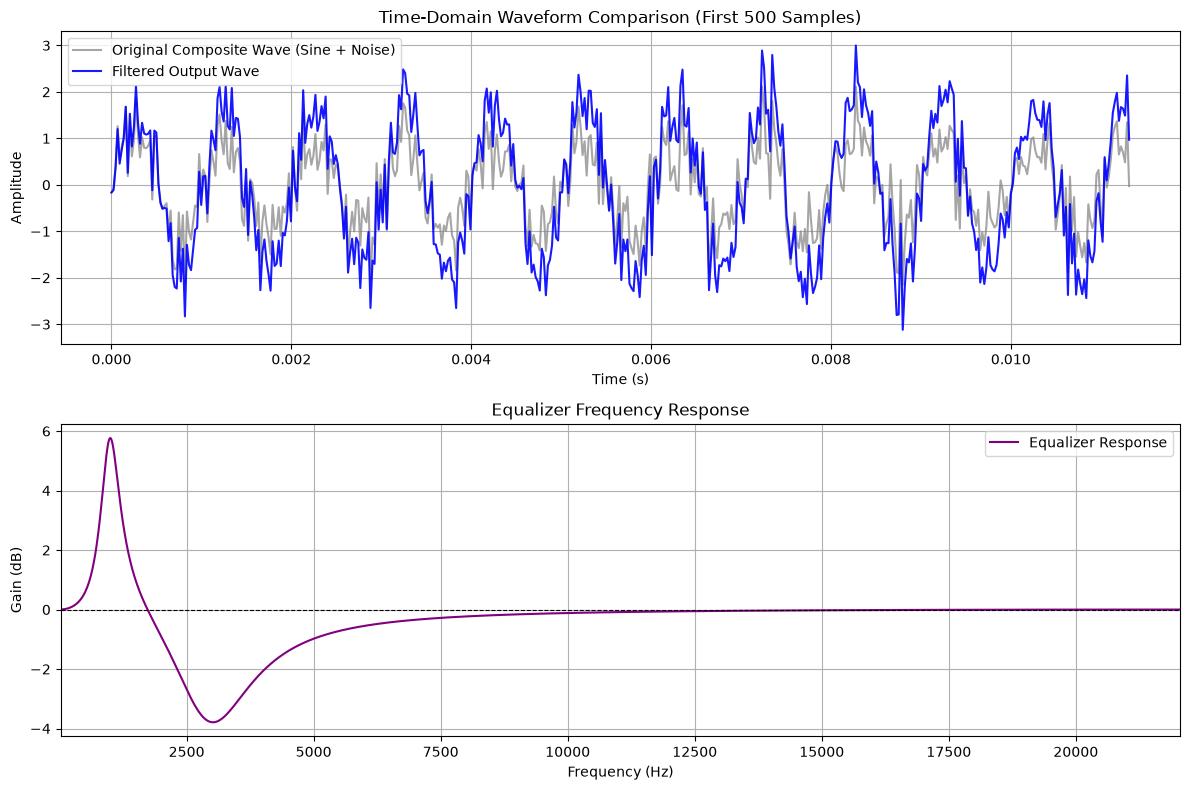

In [4]:
import matplotlib.pyplot as plt
# Frequency Response Calculation
frequency_axis = np.linspace(0, Nyquist, 4096)

H_response = np.ones(len(frequency_axis), dtype=complex)

for band in eq_bands:

    w = 2 * np.pi * frequency_axis / sampleRate

    numerator = (
        band["B0Norm"] +
        band["B1Norm"] * np.exp(-1j * w) +
        band["B2Norm"] * np.exp(-2j * w)
    )

    denominator = (
        1 +
        band["A1Norm"] * np.exp(-1j * w) +
        band["A2Norm"] * np.exp(-2j * w)
    )

    H_response *= numerator / denominator

if not np.all(np.isfinite(H_response)):
    raise ValueError("Invalid frequency response detected.")

magnitude_dB = 20 * np.log10(
    np.maximum(np.abs(H_response), 1e-12)
)

# Frequency Response Visualization
plt.figure(figsize=(12, 8))

# Top Subplot: Time-Domain Waveform (Zoomed into first 500 samples to see the wave detail)
plt.subplot(2, 1, 1)
plt.plot(t[:500], composite_wave[:500], label="Original Composite Wave (Sine + Noise)", color="gray", alpha=0.7)
plt.plot(t[:500], final_output[:500], label="Filtered Output Wave", color="blue", alpha=0.9)
plt.title("Time-Domain Waveform Comparison (First 500 Samples)")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.legend()

# Bottom Subplot: Equalizer Frequency Response
plt.subplot(2, 1, 2)
plt.plot(frequency_axis, magnitude_dB, label="Equalizer Response", color="purple")
plt.axhline(y=0, color="black", linestyle="--", linewidth=0.8)
plt.title("Equalizer Frequency Response")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Gain (dB)")
plt.grid(True)
plt.xlim(20, Nyquist)
plt.legend()

plt.tight_layout()
plt.show()